<a href="https://colab.research.google.com/github/ChanceResearcher/skills-review-pull-requests/blob/main/GNR_PowerLaw_Task3_Conflicts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import json
import os
from tqdm.notebook import tqdm
import concurrent.futures
import random # Added for GNR_SimulationVm
from collections import Counter # Added for GNR_SimulationVm

# The same seed I saw the models using.
np.random.seed(12345) # Moved from initial setup cell

# These helper functions were previously in cell c51ed039, but are moved here
# to ensure they are defined when run_conflict_analysis_and_plot_thresholds is called.
N = 100
alphaX = np.arange(0, 4.1, 0.1) # Corresponds to alphaMax = 4, with 0.1 increments
rX = np.arange(0, 1.01, 0.01)   # Corresponds to r values from 0.0 to 1.0 with 0.01 increments
trials = 100

# Define the filename for saving intermediate results
RESULTS_FILENAME = 'simulation_results.json'

# GNR_SimulationVm, moved here from EXmpbCpfyTjD
def GNR_SimulationVm(NumNodes, alpha, r_probability):
    NumNodes += 1

    #Initialize the arrays for the simulation.

    # NodeConnections[i] will be a list of nodes that node i connects to.
    NodeConnections = [[] for _ in range(NumNodes)]

    #Initial Conditions: Node 1 connected to Node 2, Node 2 connected to Node 1.
    NodeConnections[1].append(2)
    NodeConnections[2].append(1)
    conflicts = 0
    totalLinks = 2

    #For each new node, randomly select a number of nodes to connect to,
    #out of a power law distribution.
    #Then, with probability r, connect to the ancestor of that node instead.

    for NodeID in range(3, NumNodes):
        # Determine possible values for 'm' (number of connections for the new node)
        # 'm' must be at least 1. Maximum 'm' can be NodeID - 1 (connections to all existing nodes).
        m_possible_values = np.arange(1, NodeID)

        # Calculate unnormalized probabilities based on the power law: P(m) ~ m^(-alpha)
        # Use the 'alpha' parameter passed to the GNR_SimulationVm function.
        unnormalized_probabilities_m = 1.0 / (m_possible_values ** alpha)

        # Normalize probabilities to sum to 1
        probabilities_m = unnormalized_probabilities_m / np.sum(unnormalized_probabilities_m)

        # Sample 'm' (the number of connections this new node will make
        m = np.random.choice(m_possible_values, p=probabilities_m)
        for j in range(int(m)): # Ensure m is an integer for range
            NewNode = np.random.randint(1, NodeID)
            if random.random() < r_probability:
                randomAncestor = NodeConnections[NewNode][np.random.randint(0, len(NodeConnections[NewNode]))]
                NewNode = randomAncestor

            NodeConnections[NodeID].append(NewNode)

            totalLinks += 1

        element_counts = Counter(NodeConnections[NodeID][:])
        conflicts += sum(freq - 1 for element, freq in element_counts.items() if freq > 1)

    return NodeConnections, conflicts, totalLinks

def run_single_simulation(N_nodes, alpha_val, r_val, num_trials):
    """
    Helper function to run GNR_SimulationVm multiple times for a single (alpha, r) pair.
    """
    conflictsToAverage = 0
    TotalLinksToAverage = 0

    for _ in range(0, num_trials):
        # GNR_SimulationVm is assumed to be available from a previous cell
        _, conflicts, TotalLinks = GNR_SimulationVm(N_nodes, alpha_val, r_val)
        conflictsToAverage += conflicts
        TotalLinksToAverage += TotalLinks

    if TotalLinksToAverage > 0: # Avoid division by zero
        conflictsAverage = conflictsToAverage / num_trials
        TotalLinksAverage = TotalLinksToAverage / num_trials
        percentage_conflicts = (conflictsAverage / TotalLinksAverage) * 100
    else:
        percentage_conflicts = 0.0

    return alpha_val, r_val, percentage_conflicts

# New top-level helper function for multiprocessing map
def _multiprocess_simulation_wrapper(args):
    """
    Wrapper function to adapt run_single_simulation for multiprocessing.
    Takes a tuple (N_nodes, alpha_val, r_val, num_trials) as input.
    """
    N_nodes, alpha_val, r_val, num_trials = args
    return run_single_simulation(N_nodes, alpha_val, r_val, num_trials)

def calculate_r_thresholds_multiprocess(N_nodes, alpha_vals, r_vals, num_trials, conflict_threshold):
    """
    Calculates the minimum redirection probability (r) for each alpha value
    at which the percentage of conflicts exceeds a given threshold, using multiprocessing.

    Args:
        N_nodes (int): Number of nodes in the simulation.
        alpha_vals (np.ndarray): Array of alpha values to test.
        r_vals (np.ndarray): Array of r values to test.
        num_trials (int): Number of trials for each (alpha, r) simulation.
        conflict_threshold (float): The percentage of conflicts threshold.

    Returns:
        dict: A dictionary where keys are alpha values and values are the
              minimum r-thresholds for the given conflict_threshold.
    """
    results_for_threshold = {}
    all_simulation_results = []

    # Prepare a list of all (N_nodes, alpha, r, num_trials) tuples to simulate
    tasks = []
    for alpha_val in alpha_vals:
        for r_val in r_vals:
            tasks.append((N_nodes, alpha_val, r_val, num_trials))

    # Use ProcessPoolExecutor for parallel execution
    with concurrent.futures.ProcessPoolExecutor() as executor:
        # Map the _multiprocess_simulation_wrapper function to all tasks
        # Use tqdm to show a progress bar for the parallel execution
        for alpha_val, r_val, percentage_conflicts in tqdm(
            executor.map(_multiprocess_simulation_wrapper, tasks),
            total=len(tasks), desc="Simulating (alpha, r) pairs"
        ):
            all_simulation_results.append((alpha_val, r_val, percentage_conflicts))

    # Process the results to find r-thresholds for the given conflict_threshold
    for alpha_val in alpha_vals:
        r_above_threshold_for_alpha = []
        for res_alpha, res_r, res_percent_conflicts in all_simulation_results:
            if res_alpha == alpha_val and res_percent_conflicts > conflict_threshold:
                r_above_threshold_for_alpha.append(res_r)

        if r_above_threshold_for_alpha:
            results_for_threshold[alpha_val] = min(r_above_threshold_for_alpha)

    return results_for_threshold

def run_conflict_analysis_and_plot_thresholds(
    threshold_percentages_to_analyze,
    N_nodes=None,
    alpha_range=None,
    r_range=None,
    num_trials=None,
    results_filename='simulation_results.json'
):
    """
    Performs GNR simulations to analyze conflict thresholds and plots the results
    for a given list of threshold percentages.

    This function leverages helper functions (run_single_simulation,
    _multiprocess_simulation_wrapper, calculate_r_thresholds_multiprocess)
    and global parameters (N, alphaX, rX, trials) defined in previous cells.

    Args:
        threshold_percentages_to_analyze (list): A list of conflict percentage
                                                 thresholds (float) to analyze and plot.
        N_nodes (int): Number of nodes in the simulation. Defaults to global N from previous cell.
        alpha_range (np.ndarray): Array of alpha values. Defaults to global alphaX from previous cell.
        r_range (np.ndarray): Array of r values. Defaults to global rX from previous cell.
        num_trials (int): Number of trials for each (alpha, r) simulation. Defaults to global trials from previous cell.
        results_filename (str): The filename to save/load intermediate results.
                                Defaults to 'simulation_results.json'.

    Returns:
        dict: A dictionary containing the r-thresholds for each alpha value
              for all analyzed conflict thresholds.
    """
    # Use global variables if arguments are not provided
    # These global variables (N, alphaX, rX, trials) are expected to be defined
    # in an earlier executed cell (e.g., EH1r8_UOzCXj)
    N_nodes = N_nodes if N_nodes is not None else N
    alpha_range = alpha_range if alpha_range is not None else alphaX
    r_range = r_range if r_range is not None else rX
    num_trials = num_trials if num_trials is not None else trials

    all_threshold_results = {}

    if os.path.exists(results_filename):
        with open(results_filename, 'r') as f:
            loaded_results_str_keys = json.load(f)
            all_threshold_results = {float(k): {float(ak): av for ak, av in v.items()} for k, v in loaded_results_str_keys.items()}
        print(f"Loaded previous results from {results_filename}. Proceeding with remaining simulations.")
    else:
        print(f"No previous results found at {results_filename}. Starting new simulations.")

    print("Starting extensive simulations for different conflict thresholds using multiprocessing.")

    for current_threshold in sorted(threshold_percentages_to_analyze):
        if current_threshold in all_threshold_results:
            print(f"\nResults for conflicts > {current_threshold}% already exist. Skipping calculation.")
        else:
            print(f"\nCalculating r-thresholds for conflicts > {current_threshold}%...")

            current_results = calculate_r_thresholds_multiprocess(N_nodes, alpha_range, r_range, num_trials, current_threshold)
            all_threshold_results[current_threshold] = current_results

    print(f"\n--- Generating final plot for specified conflict thresholds ---")
    plt.figure(figsize=(12, 8))

    for threshold_val in sorted(all_threshold_results.keys()):
        results_dict = all_threshold_results[threshold_val]
        sorted_items = sorted(results_dict.items())
        alphas_to_plot = [item[0] for item in sorted_items]
        r_thresholds_to_plot = [item[1] for item in sorted_items]

        if alphas_to_plot:
            plt.plot(alphas_to_plot, r_thresholds_to_plot, marker='o', linestyle='-', label=rf'Conflicts > {threshold_val}\%')

            # Perform linear regression if there are enough points
            if len(alphas_to_plot) >= 2:
                slope, intercept = np.polyfit(alphas_to_plot, r_thresholds_to_plot, 1)
                plt.plot(alphas_to_plot, slope * np.array(alphas_to_plot) + intercept,
                         linestyle='--', color='gray', alpha=0.7, label=f'Fit (Slope={slope:.2f}, Intercept={intercept:.2f})')
                print(f"\nFor Conflicts > {threshold_val}%: ")
                print(f"  Best-fit line: Slope = {slope:.4f}, Intercept = {intercept:.4f}")


    plt.xlabel(r'Alpha $\alpha$')
    plt.ylabel(r'Threshold Redirection Probability $r_{\mathrm{threshold}}$')
    plt.title(r'Threshold Redirection Probability $r_{\mathrm{threshold}}$ vs Alpha $\alpha$ for Different Conflict Thresholds')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(title='Conflict Threshold')

    if alpha_range.size > 0:
        plt.xticks(np.arange(np.floor(alpha_range.min()), np.ceil(alpha_range.max()) + 0.5, 0.5))

    # Set y-axis limit to 0-1 as requested
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()

    print("\n--- Analysis Complete and Plot Displayed ---")
    return all_threshold_results

In [4]:
# Proof of model working:

num_nodes = 10
alpha = 1
r = 0.3
trials = 1  # Increased trials for better statistical representation
conflictsToAverage = 0
TotalLinksToAverage = 0
for i in range(trials):
  NodeConnections, conflicts, TotalLinks = GNR_SimulationVm(num_nodes, alpha, r)
  conflictsToAverage += conflicts
  TotalLinksToAverage += TotalLinks
conflictsAverage = conflictsToAverage/trials
TotalLinksAverage = TotalLinksToAverage/trials
print('Number of Nodes: ', num_nodes, ' r = ', r, ' alpha = ', alpha, ' trials = ', trials)
print('Number of Conflicts: ', conflictsAverage)
print('Total Links: ', TotalLinksAverage)
print('Fraction of Conflicts of Total Links: ', conflictsAverage/TotalLinksAverage)
percentage_conflicts = (conflictsAverage / TotalLinksAverage) * 100
print(f"Percentage of conflicts: {percentage_conflicts:.2f}%")
print("Nodes connected to: ", NodeConnections)
print("Check:")
print("Check 1: Fraction is Number of Conflicts / Total Links")
print("Check 2: Percentage is 100 multiplied by the fraction.")
print("Check 3: 'Nodes connected to' starts at unused zero.")
print("Check 4: Node 1 is connected to Node 2, meaning 1's spot contains 2")
print("Check 5: Node 2 is connected to Node 1, meaning 2's spot contains 1")
print("Check 6: The number of nodes any later node connects to is less than the index number of said node.")
print("Check 7: Every node a node connects to is less than the node index ID number, meaning it only connects to earlier nodes.")
print("Check 8: Add up the total number of links, meaning every value in 'Nodes to connect to'")
print("Check 9: Find and add up the number of conflicts, by looking for double numbers in [] brackets.")

Number of Nodes:  10  r =  0.3  alpha =  1  trials =  1
Number of Conflicts:  3.0
Total Links:  22.0
Fraction of Conflicts of Total Links:  0.13636363636363635
Percentage of conflicts: 13.64%
Nodes connected to:  [[], [2], [1], [2, 1], [3], [3, 2, 1], [4, 1, 4, 2, 1], [1], [4, 4], [6, 2, 4], [1, 4, 6]]
Check:
Check 1: Fraction is Number of Conflicts / Total Links
Check 2: Percentage is 100 multiplied by the fraction.
Check 3: 'Nodes connected to' starts at unused zero.
Check 4: Node 1 is connected to Node 2, meaning 1's spot contains 2
Check 5: Node 2 is connected to Node 1, meaning 2's spot contains 1
Check 6: The number of nodes any later node connects to is less than the index number of said node.
Check 7: Every node a node connects to is less than the node index ID number, meaning it only connects to earlier nodes.
Check 8: Add up the total number of links, meaning every value in 'Nodes to connect to'
Check 9: Find and add up the number of conflicts, by looking for double numbers i

Mounted at /content/drive
Successfully loaded raw simulation data from /content/drive/MyDrive/Colab Notebooks/raw_simulation_data_1.json.

Calculating r-thresholds from raw data for all conflict percentages...
Finished calculating r-thresholds.

For Conflicts > 0.0%:
  Linear Fit: Slope = 0.0000, Intercept = 0.0000, R-squared = nan

For Conflicts > 5.0%:
  Linear Fit: Slope = 0.2754, Intercept = -0.2968, R-squared = 0.8053

For Conflicts > 10.0%:
  Linear Fit: Slope = 0.3388, Intercept = -0.2970, R-squared = 0.8538

For Conflicts > 15.0%:
  Linear Fit: Slope = 0.3823, Intercept = -0.2693, R-squared = 0.8951

For Conflicts > 20.0%:
  Linear Fit: Slope = 0.4145, Intercept = -0.2187, R-squared = 0.9480

For Conflicts > 25.0%:
  Linear Fit: Slope = 0.3626, Intercept = 0.0124, R-squared = 0.9891

For Conflicts > 30.0%:
  Linear Fit: Slope = 0.2538, Intercept = 0.2966, R-squared = 0.9707

For Conflicts > 35.0%:
  Linear Fit: Slope = 0.2036, Intercept = 0.4414, R-squared = 0.9562

For Conflic

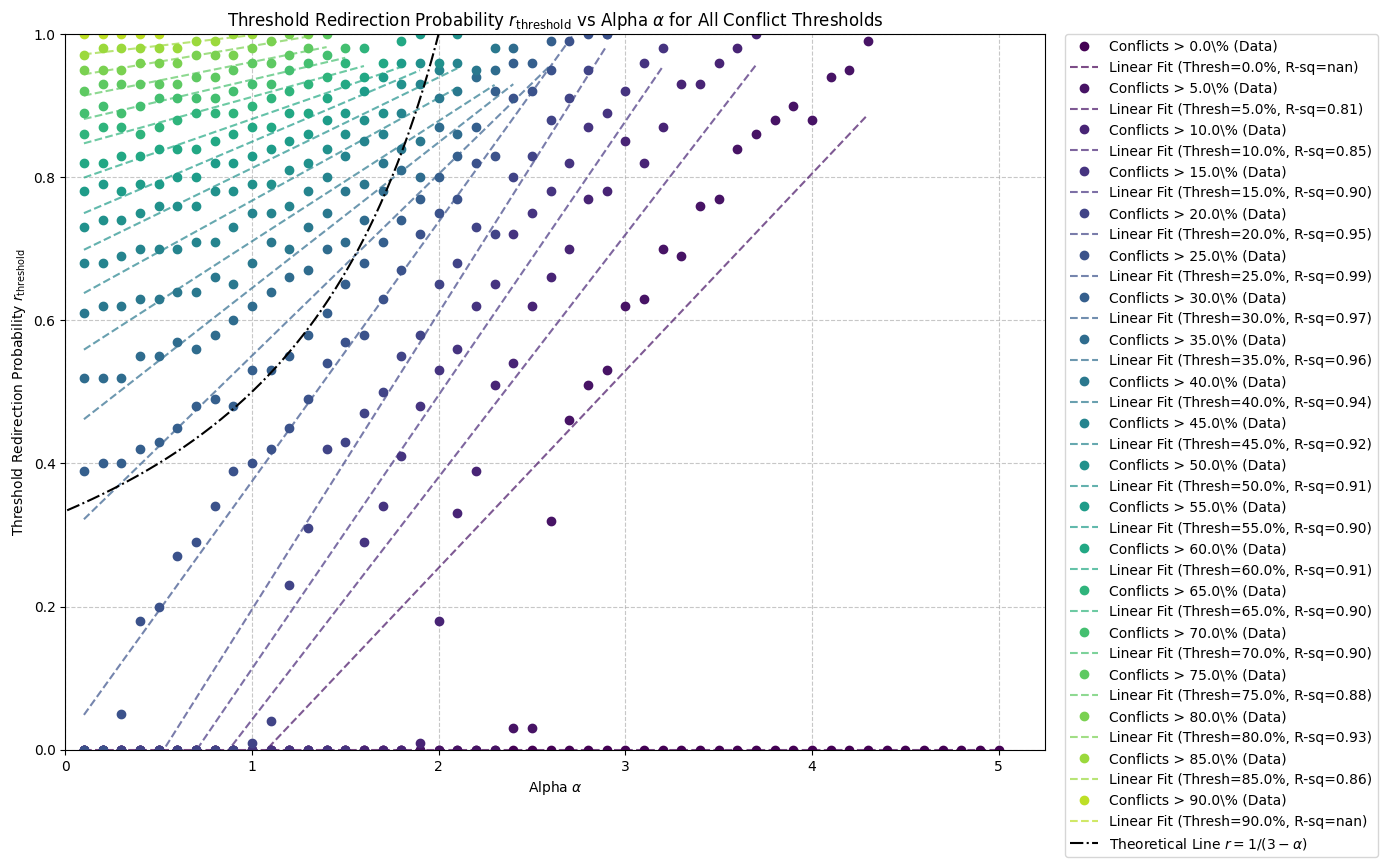

In [5]:
# Task: Calculate slope and intercept of best fit lines for each conflict threshold.

import numpy as np
import matplotlib.pyplot as plt
import json
import os
from google.colab import drive
from scipy.stats import linregress

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define the path to your JSON file on Google Drive
# IMPORTANT: Adjust this path if your file is in a different location
json_file_path = '/content/drive/MyDrive/Colab Notebooks/raw_simulation_data_1.json'

# 3. Load the raw simulation results from the JSON file
results_all_raw = {}
if os.path.exists(json_file_path):
    with open(json_file_path, 'r') as f:
        loaded_results_str_keys = json.load(f)
        # Convert string keys back to float for alpha and r values
        # Assuming the structure is {alpha_str: {r_str: {'total_conflicts': ..., 'total_links': ..., 'num_runs': ...}}}
        results_all_raw = {float(k_alpha): {float(k_r): v_data for k_r, v_data in v_alpha.items()} for k_alpha, v_alpha in loaded_results_str_keys.items()}
    print(f"Successfully loaded raw simulation data from {json_file_path}.")
else:
    print(f"Error: File not found at {json_file_path}. Please check the path and try again.")


# 4. Define the conflict thresholds to analyze (same as in g4Ko2Ho2TxKg)
threshold_percentages_to_analyze = [
    0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0,
    50.0, 55.0, 60.0, 65.0, 70.0, 75.0, 80.0, 85.0, 90.0, 95.0, 100.0
]

# 5. Calculate r_thresholds for each alpha and each conflict threshold from the raw data
calculated_r_thresholds = {threshold: {} for threshold in threshold_percentages_to_analyze}

if results_all_raw:
    alpha_vals_raw = sorted(results_all_raw.keys())

    # Prepare for progress display
    print("\nCalculating r-thresholds from raw data for all conflict percentages...")

    for threshold_val in sorted(threshold_percentages_to_analyze):
        for alpha_val in alpha_vals_raw:
            r_above_threshold_for_alpha = []

            r_vals_raw = sorted(results_all_raw[alpha_val].keys())
            for r_val in r_vals_raw:
                raw_data = results_all_raw[alpha_val][r_val]
                total_conflicts = raw_data['total_conflicts']
                total_links = raw_data['total_links']

                if total_links > 0:
                    percentage_conflicts = (total_conflicts / total_links) * 100
                else:
                    percentage_conflicts = 0.0

                if percentage_conflicts > threshold_val:
                    r_above_threshold_for_alpha.append(r_val)

            if r_above_threshold_for_alpha:
                calculated_r_thresholds[threshold_val][alpha_val] = min(r_above_threshold_for_alpha)
            else:
                # If no r value crosses the threshold, set to NaN or skip for this alpha
                calculated_r_thresholds[threshold_val][alpha_val] = np.nan
    print("Finished calculating r-thresholds.")

# 6. Plotting all thresholds with linear fits and theoretical line
if calculated_r_thresholds:
    plt.figure(figsize=(14, 9))

    # Use plt.colormaps for Matplotlib 3.7+ compatibility
    colors = plt.colormaps['viridis'](np.linspace(0, 1, len(calculated_r_thresholds)))

    # Plot data points and linear fits for each threshold
    for i, threshold_val in enumerate(sorted(calculated_r_thresholds.keys())):
        # Removed condition to plot only thresholds > 70%

        results_dict = calculated_r_thresholds[threshold_val]
        # Filter out NaN values before sorting and plotting
        filtered_items = [(alpha, r_thresh) for alpha, r_thresh in results_dict.items() if not np.isnan(r_thresh)]

        if not filtered_items: # Skip if no valid data for this threshold
            print(f"\nFor Conflicts > {threshold_val:.1f}%: No valid r-thresholds to plot.")
            continue

        sorted_items = sorted(filtered_items)
        alphas_to_plot = np.array([item[0] for item in sorted_items])
        r_thresholds_to_plot = np.array([item[1] for item in sorted_items])

        # Filter out zero/problematic alpha values for regression (can cause issues with log for power law, or just bad fit points)
        valid_indices = (alphas_to_plot > 0) # Keep alphas > 0
        filtered_alphas = alphas_to_plot[valid_indices]
        filtered_r_thresholds = r_thresholds_to_plot[valid_indices]

        if len(filtered_alphas) > 1: # Need at least 2 points for linear regression
            # Plot original data points
            plt.plot(filtered_alphas, filtered_r_thresholds, 'o', color=colors[i], label=rf'Conflicts > {threshold_val:.1f}\% (Data)')

            # Perform linear regression
            slope_linear, intercept_linear, r_value, p_value, std_err = linregress(filtered_alphas, filtered_r_thresholds)
            linear_fit_curve = slope_linear * filtered_alphas + intercept_linear
            plt.plot(filtered_alphas, linear_fit_curve, '--', color=colors[i], alpha=0.7,
                     label=f'Linear Fit (Thresh={threshold_val:.1f}%, R-sq={r_value**2:.2f})')
            print(f"\nFor Conflicts > {threshold_val:.1f}%:")
            print(f"  Linear Fit: Slope = {slope_linear:.4f}, Intercept = {intercept_linear:.4f}, R-squared = {r_value**2:.4f}")
        elif len(filtered_alphas) == 1:
            # Plot single data point without fit
            plt.plot(filtered_alphas, filtered_r_thresholds, 'o', color=colors[i], label=rf'Conflicts > {threshold_val:.1f}\% (Data)')
            print(f"\nFor Conflicts > {threshold_val:.1f}%: Only one data point available, skipping linear fit.")
        else:
            print(f"\nFor Conflicts > {threshold_val:.1f}%: No valid data points to plot.")

    # Plot the theoretical line r = 1 / (3 - alpha)
    # Choose an alpha range carefully to avoid singularity at alpha = 3
    # Assuming alpha range from 0 to less than 3 for this theoretical line to be meaningful
    alpha_theoretical = np.linspace(0.01, 2.99, 500) # Start from small positive to avoid issues if alpha=0 was included earlier
    r_theoretical = 1 / (3 - alpha_theoretical)
    plt.plot(alpha_theoretical, r_theoretical, '-.', color='black', label=r'Theoretical Line $r = 1 / (3 - \alpha)$')

    plt.xlabel(r'Alpha $\alpha$')
    plt.ylabel(r'Threshold Redirection Probability $r_{\mathrm{threshold}}$')
    plt.title(r'Threshold Redirection Probability $r_{\mathrm{threshold}}$ vs Alpha $\alpha$ for All Conflict Thresholds')
    plt.grid(True, linestyle='--', alpha=0.7)

    # Move the legend off the graph
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

    plt.ylim(0, 1) # Retain y-axis limit as previously requested
    plt.xlim(left=0) # Ensure alpha starts from 0 or positive
    plt.tight_layout() # Adjust layout to prevent legend overlap
    plt.show()
else:
    print("No data to plot. Please ensure the JSON file was loaded and r-thresholds were calculated correctly.")

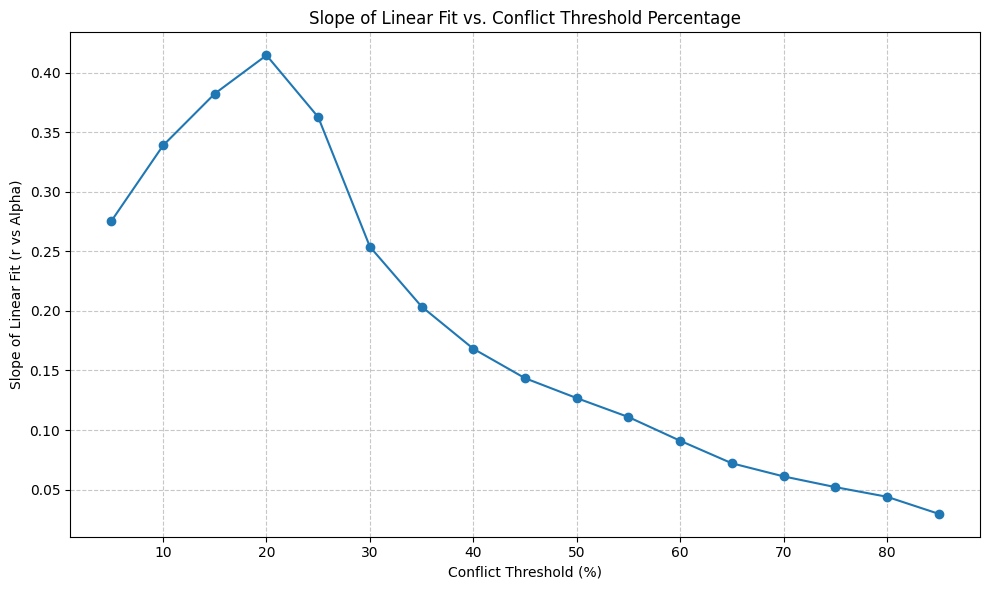

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Data extracted from the output of cell rUIEbAe0SLa_
threshold_percentages = np.array([
    0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0,
    50.0, 55.0, 60.0, 65.0, 70.0, 75.0, 80.0, 85.0, 90.0
])

slopes = np.array([
    0.0000, 0.2754, 0.3388, 0.3823, 0.4145, 0.3626, 0.2538, 0.2036, 0.1682, 0.1435,
    0.1268, 0.1109, 0.0910, 0.0721, 0.0611, 0.0521, 0.0440, 0.0297, 0.0000
])

# R-squared values to potentially filter or use for plotting
r_squared_values = np.array([
    np.nan, 0.8053, 0.8538, 0.8951, 0.9480, 0.9891, 0.9707, 0.9562, 0.9356, 0.9227,
    0.9142, 0.8973, 0.9123, 0.9019, 0.9034, 0.8773, 0.9254, 0.8560, np.nan
])

# Filter out NaN R-squared values (which correspond to 0.0 slopes with no meaningful fit)
valid_indices = ~np.isnan(r_squared_values)
filtered_threshold_percentages = threshold_percentages[valid_indices]
filtered_slopes = slopes[valid_indices]
filtered_r_squared = r_squared_values[valid_indices]

plt.figure(figsize=(10, 6))
plt.plot(filtered_threshold_percentages, filtered_slopes, marker='o', linestyle='-')

plt.xlabel('Conflict Threshold (%)')
plt.ylabel('Slope of Linear Fit (r vs Alpha)')
plt.title('Slope of Linear Fit vs. Conflict Threshold Percentage')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [20]:
intercepts = np.array([
    0.0000, -0.2968, -0.2970, -0.2693, -0.2187,  0.0124,  0.2966,  0.4414,  0.5421,  0.6236,
    0.6858,  0.7386,  0.7902,  0.8400,  0.8751,  0.9088,  0.9392,  0.9687,  1.0000
])

negative_intercept_indices = np.where(intercepts < 0)[0]
thresholds_with_negative_intercepts = threshold_percentages[negative_intercept_indices]

print("Part A: Threshold percentages with negative intercepts:")
for threshold in thresholds_with_negative_intercepts:
    print(f"{threshold:.1f}%")

max_slope_index = np.argmax(filtered_slopes)
max_slope_x = filtered_threshold_percentages[max_slope_index]
max_slope_y = filtered_slopes[max_slope_index]

print(f"Part B/C: Data point with maximum slope: x = {max_slope_x:.2f}%, y = {max_slope_y:.4f}")

print("Part C: 0.4 as a fraction is 4/10 = 2/5")

index_90_percent = np.where(threshold_percentages == 90.0)[0]

if len(index_90_percent) > 0:
    x_90_percent = threshold_percentages[index_90_percent[0]]
    y_90_percent = slopes[index_90_percent[0]]
    print(f"Part D: Data point for slope of 0.0000: x = {x_90_percent:.2f}%, y = {y_90_percent:.4f}")
else:
    print("90% threshold not found in the original data.")

Part A: Threshold percentages with negative intercepts:
5.0%
10.0%
15.0%
20.0%
Part B/C: Data point with maximum slope: x = 20.00%, y = 0.4145
Part C: 0.4 as a fraction is 4/10 = 2/5
Part D: Data point for slope of 0.0000: x = 90.00%, y = 0.0000
